# Tiga Wajah Member: Segmentasi yang Stabil dan Bisa Ditindaklanjuti

Segmentasi ini ada untuk satu hal: playbook targeting butuh kelompok member yang bisa diberi perlakuan berbeda. Syaratnya dua — segmen harus **stabil** (bukan artefak periode atau seed acak) dan **bisa ditindaklanjuti** (setiap segmen punya satu aksi yang diturunkan dari aturan, bukan opini).

Jujur di depan: data perilaku belanja seperti ini tidak punya klaster yang tajam — silhouette-nya rendah di semua k, itu normal. Jadi pemilihan k diputuskan oleh **stabilitas lintas seed dan lintas paruh periode** (ARI), bukan oleh silhouette semata. Hasilnya tiga segmen yang bertahan: **mesin pertumbuhan** (44% member, sehat di semua sinyal), **promo-dependent** (39%, paling bergantung diskon), dan **rentan hilang** (17%, empat dari sepuluh anggotanya sudah melewati ambang churn).

## 0. Setup

In [1]:
def raw_feature_cols(raw, departments):
    return seg.raw_feature_frame(raw, departments).columns

import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.segments as seg
from src.features import PROCESSED_DIR, save_parquet

panel = pd.read_parquet(PROCESSED_DIR / "hh_week.parquet")
whitespace = pd.read_parquet(PROCESSED_DIR / "hh_whitespace.parquet")
raw_full, departments = seg.build_segment_features(panel, *seg.FULL_WEEKS)
raw_p1, _ = seg.build_segment_features(panel, *seg.P1_WEEKS, departments=departments)
raw_p2, _ = seg.build_segment_features(panel, *seg.P2_WEEKS, departments=departments)
print(f"fitur: {len(raw_full):,} member x {len(raw_feature_cols(raw_full, departments))} dimensi")

fitur: 2,500 member x 48 dimensi


## 1. Ruang fitur — dan dua anggota yang nyaris merusak semuanya

Setiap member digambarkan oleh RFM (frekuensi, nilai belanja per minggu aktif, recency — semuanya log-transform), rata-rata `promo_share`, dan bauran belanja sebagai **share 44 department**. Dua member dengan belanja ekstrem (sampai $173 per minggu aktif) berhasil membentuk klaster sendiri di setiap percobaan — K-means memang begitu. Winsorisasi dicoba dan justru menciptakan artefak baru (member yang terpotong di persentil sama menjadi identik dan membentuk mikro-klaster tiruan). Solusi akhirnya sederhana dan standar: **top-1% spender tidak ikut fitting** tetapi tetap ditugaskan ke centroid terdekat, dan klaster beranggota < 30 dikonsolidasikan — tidak ada segmen yang terlalu kecil untuk dilaporkan.

In [2]:
def raw_feature_cols(raw, departments):
    return seg.raw_feature_frame(raw, departments).columns

core = seg.core_mask(raw_full)
print(f"core population: {int(core.sum()):,} member | dikecualikan dari fitting: {int((~core).sum())} (top-1% spend, tetap di-assign)")
display(raw_full.loc[~core, ["household_key", "frequency", "monetary"]].sort_values("monetary", ascending=False).head(5))

core population: 2,475 member | dikecualikan dari fitting: 25 (top-1% spend, tetap di-assign)


,household_key,frequency,monetary
1022,1023,84,429.682500
1608,1609,95,266.605263
2321,2322,91,233.301429
1452,1453,87,215.698736
972,973,59,202.074746


## 2. Memilih k: yang menang adalah yang tidak goyah

Silhouette rendah di semua k (0,02–0,07) — tidak ada struktur tajam, dan itu justru informasi. Pemutusnya stabilitas: label dari model paruh pertama data vs model paruh kedua (ARI, median atas 5 seed). k=5 yang paling rapat rentang seed-nya (0,641–0,687); setelah konsolidasi mikro-klaster, tiga segmen efektif yang tersisa semuanya besar dan stabil.

In [3]:
sil = seg.silhouette_curve(raw_full, departments)
rows = []
for k in seg.K_RANGE:
    aris = seg.stability_ari(raw_p1, raw_p2, departments, k)
    segs, _, _ = seg.fit_segments(raw_full, departments, k=k)
    sizes = segs.groupby("segment").size().tolist()
    rows.append({"k": k, "silhouette": round(sil[k], 4),
                 "ari_median": round(float(np.median(aris)), 3), "ari_min": round(min(aris), 3),
                 "n_segmen_efektif": len(sizes), "min_n": min(sizes)})
curve = pd.DataFrame(rows)
display(curve)
aris_final = seg.stability_ari(raw_p1, raw_p2, departments, seg.K_FINAL)
print(f"k final = {seg.K_FINAL} | ARI median {np.median(aris_final):.3f} (min {min(aris_final):.3f}, max {max(aris_final):.3f})")

,k,silhouette,ari_median,ari_min,n_segmen_efektif,min_n
0,3,0.0570,0.671,0.635,2,1223
1,4,0.0563,0.678,0.648,2,1228
2,5,0.0304,0.646,0.641,3,429
3,6,0.0345,0.577,0.268,3,391
4,7,0.0301,0.631,0.346,3,474
5,8,0.0187,0.439,0.250,4,291


k final = 5 | ARI median 0.646 (min 0.641, max 0.687)


## 3. Ambang churn dari data, bukan dari kebiasaan

Sebuah member ditandai *churn risk* bila jarak sejak belanja terakhirnya melewati **persentil ke-95 distribusi inter-purchase gap panel ini** — hasilnya 5 minggu, angka yang keluar dari data. Sinyal sekunder *spend dropping*: rasio belanja paruh kedua terhadap paruh pertama di bawah persentil ke-10 (0,42). Gabungan keduanya menandai 14,6% member.

gap p95 = 5 minggu | rasio H2/H1 p10 = 0.419
churn risk 14.6% | spend dropping 10.0%


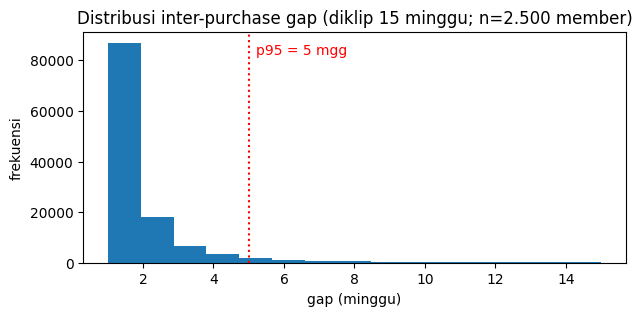

In [4]:
thresholds = seg.churn_thresholds(panel)
churn = seg.churn_flags(panel, thresholds)
print(f"gap p95 = {thresholds['gap_p95']:.0f} minggu | rasio H2/H1 p10 = {thresholds['ratio_p10']:.3f}")
print(f"churn risk {churn['churn_risk'].mean():.1%} | spend dropping {churn['spend_dropping'].mean():.1%}")

gaps = (panel[panel.has_purchase].sort_values("week_no").groupby("household_key")["week_no"].diff().dropna())
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(gaps[gaps <= 15], bins=15, color="#1f77b4")
ax.axvline(thresholds["gap_p95"], color="red", ls=":", lw=1.5)
ax.text(thresholds["gap_p95"] + 0.2, ax.get_ylim()[1] * 0.9, f"p95 = {thresholds['gap_p95']:.0f} mgg", color="red")
ax.set(title="Distribusi inter-purchase gap (diklip 15 minggu; n=2.500 member)", xlabel="gap (minggu)", ylabel="frekuensi")
plt.show()

## 4. Tiga segmen

Profilnya terbaca seperti cerita bisnis: **segmen 1** belanja paling besar dan hampir tidak ada yang berisiko hilang; **segmen 2** paling bergantung pada promo (0,23 dari nilai belanjanya didiskon) dengan churn menengah; **segmen 3** paling kecil nilai belanjanya dan 39% anggotanya sudah melewati ambang churn — kelompok yang kalau tidak dihubungi, kemungkinan besar pergi.

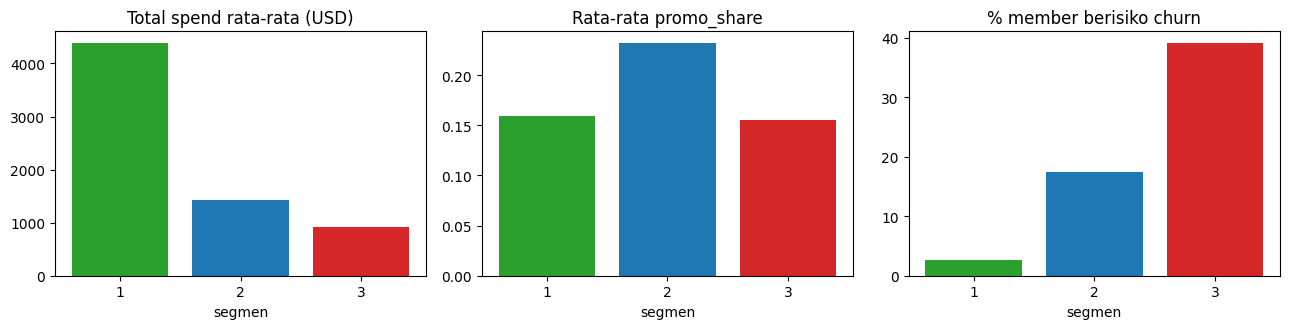

,segment,n,share_pct,mean_weekly_spend_active,mean_total_spend,promo_dependence,churn_risk_pct,spend_dropping_pct,whitespace_utama,whitespace_per_member_usd
0,1,1099,43.96,63.08,4386.10,0.16,2.64,4.00,BEEF,440.81
1,2,972,38.88,34.51,1430.88,0.23,17.39,12.76,BEERS/ALES,148.65
2,3,429,17.16,29.94,927.29,0.15,39.16,19.11,BEEF,141.37


In [5]:
segments, model, _ = seg.fit_segments(raw_full, departments)
table = seg.build_segment_table(segments, churn, whitespace, thresholds)
save_parquet(segments, PROCESSED_DIR / "segments.parquet")
save_parquet(table, PROCESSED_DIR / "segment_summary.parquet")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
metrics = [("mean_total_spend", "Total spend rata-rata (USD)"),
           ("promo_dependence", "Rata-rata promo_share"),
           ("churn_risk_pct", "% member berisiko churn")]
for ax, (col, label) in zip(axes, metrics):
    ax.bar(table["segment"].astype(str), table[col], color=["#2ca02c", "#1f77b4", "#d62728"])
    ax.set(title=label, xlabel="segmen", ylabel="")
plt.tight_layout()
plt.show()
display(table.drop(columns=["satu_aksi"]).round(2))

## 5. Satu aksi per segmen

Aksi diturunkan dari aturan tetap — bukan teks bebas: churn terkonsentrasi → program aktivasi ulang; ketergantungan promo di atas rata-rata + setengah deviasi → uji benefit non-diskon; peluang whitespace per member di atas rata-rata → dorong kategori kandidat. Kategori operator COUPON/MISC ITEMS dikecualikan dari rekomendasi (temuan fase penetrasi kategori). Semua aksi berstatus **kandidat untuk diuji**, bukan klaim penyebab.

In [6]:
display(table[["segment", "n", "whitespace_utama", "whitespace_per_member_usd", "satu_aksi"]])

,segment,n,whitespace_utama,whitespace_per_member_usd,satu_aksi
0,1,1099,BEEF,440.814545,"Dorong kategori whitespace teratas (kandidat, ..."
1,2,972,BEERS/ALES,148.645399,Uji migrasi ke benefit non-diskon — ketergantu...
2,3,429,BEEF,141.365627,Program aktivasi ulang — uji kontak pada membe...


## 6. Artefak & angka kunci

In [7]:
display(pd.DataFrame(
    [(a, f"{(PROCESSED_DIR / a).stat().st_size / 1e6:.1f} MB") for a in ("segments.parquet", "segment_summary.parquet")],
    columns=["artefak (data/processed/)", "ukuran"],
))
sizes = segments.groupby("segment").size().to_dict()
print(f"k core = {seg.K_FINAL} -> 3 segmen efektif {sizes} | ARI median {np.median(aris_final):.3f} | ambang churn = gap > {thresholds['gap_p95']:.0f} minggu")

,artefak (data/processed/),ukuran
0,segments.parquet,0.1 MB
1,segment_summary.parquet,0.0 MB


k core = 5 -> 3 segmen efektif {1: 1099, 2: 972, 3: 429} | ARI median 0.646 | ambang churn = gap > 5 minggu


## Catatan kualitas & batasan

- Segmen bersifat **deskriptif** — bukan fitur model, bukan klaim kausal; aksinya kandidat untuk diuji (holdout), bukan janji.
Silhouette rendah di semua k: struktur segmen lembut. Yang menjadi bukti kelayakannya adalah stabilitas (ARI 0,646 lintas seed dan lintas paruh periode), dan itu pun berarti "cukup stabil", bukan "tajam".
- Fitur share department bersifat komposisional (jumlah 1); transformasi log-ratio tidak dipakai demi kesederhanaan — dicatat sebagai batasan.
- Top-1% spender dikecualikan dari fitting dan ditugaskan ke centroid terdekat; klaster < 30 dikonsolidasikan — dua penanganan outlier ini terdokumentasi di decision log.
- Ambang churn (gap p95 = 5 minggu) dan dropping (rasio p10 = 0,42) berasal dari distribusi panel ini; angka bulat tidak dipakai.
- Semua nominal USD historis; segmen dihitung dari periode penuh (deskriptif, bukan fitur model).